# 2.3 メインメモリ (Main Memory Architecture)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/2/2.3_Main_Memory_Architecture.ipynb)

本節では、名著『ゼロからのOS自作入門』第2章「EDK II入門とメモリマップ」の **2.3「メインメモリ」** を徹底解説します。

前節（2.2節）では、UEFI公式開発キット EDK II を導入し、UEFIアプリケーション `BOOTX64.EFI` から画面に `"Hello, Mikan World!"` を出力することに成功しました。  
しかし、ここから本格的な **OSカーネル（Kernel）** を自作し起動するためには、避けて通れない最大の関門があります。それが **「コンピュータのメインメモリの物理構造を正しく把握すること」** です。

「メモリなんて、空いている番地にプログラムを置いて動かせばいいのではないか？」と思うかもしれません。しかし、現実のコンピュータ（x86-64 アーキテクチャ）の物理メモリは、**決して平坦で連続した使い放題の空間ではありません**。

本ノートブックでは、書籍や外部仕様書を開かなくても、物理アドレス空間の構造、RAMとMMIOの決定的な違い、メモリホールの数理、そしてなぜ次節で「メモリマップ（Memory Map）」を取得しなければならないのかを、完全自己完結で深く理解できるように解説・検証します。

---

### 📋 本節の学習目標と到達基準 (Definition of Done)
1. **メインメモリと物理アドレス空間（Physical Address Space）の本質**:
   - CPUから見た「メモリアドレス」が、必ずしも本物のRAM（DRAM）に繋がっているわけではない理由を説明できる。
2. **RAM vs MMIO (Memory-Mapped I/O) のメカニズム**:
   - GPUのフレームバッファやPCIeデバイス、Local APICなどの周辺機器が物理アドレス空間にどのようにマッピングされ、通常のRAMとどう区別されるかを理解する。
3. **メモリスパース性とホール（Memory Hole）の数理**:
   - 32ビット時代の名残である「4GB直下のPCIホール」や、メモリリマッピングによってRAMが分断される仕組みを数理・ビット幅から導出できる。
4. **レガシー領域（1MB以下）の歴史的構造**:
   - IVT, BDA, EBDA, VGA VRAM, BIOS ROM などの配置を把握し、現代の64ビットUEFIシステムとの関係を理解する。
5. **C++20 / Python によるアドレス空間シミュレーション**:
   - アドレス境界・4KiBページアライメント・重複判定・空きRAM探索アルゴリズムを対話的に実行・検証する。


## 2.3.1 なぜOSはメインメモリの全体像を知る必要があるのか？（動機と課題）

### 前節までの到達点と直面する壁
前節（2.2節）までの私たちは、UEFI BIOSの強力なランタイム支援を受け、ファームウェア関数 `Print(L"Hello, Mikan World!\n");` を呼び出すだけで画面に文字を表示できました。  
この段階では、UEFIがメモリ管理・スタック確保・文字列出力プロトコルをすべてバックグラウンドで面倒を見てくれていたため、私たちは「メモリが物理的にどう配置されているか」を気にする必要がありませんでした。

しかし、第3章以降で私たちが目指すのは **「独自のOSカーネル（MikanOS）をストレージから読み込み、CPUの制御をファームウェアからカーネルへ恒久的に移譲すること」** です。

カーネルを起動するためには、以下の物理メモリ操作が不可欠となります：
1. **カーネル実行可能バイナリ（ELF）を格納する物理メモリ領域の確保**
2. **カーネルが動作するための独立スタック領域の確保**
3. **動的メモリ割り当て（ヒープ / `malloc` / `new`）のための空き領域の管理**
4. **仮想記憶（Paging / 4階層ページテーブル）を構築するための物理フレーム（4KiBページ）の確保**

```
+-------------------------------------------------------------------------+
| 素朴な疑問:                                                             |
| 「物理アドレス 0x00100000 (1MB) や 0x10000000 (256MB) あたりに適当に     |
|  カーネルを読み込んでジャンプすれば動くのではないか？」                 |
+-------------------------------------------------------------------------+
                                    │
                                    ▼
+─────────────────────────────────────────────────────────────────────────+
| 破滅的結末 (Hardware Trap & System Crash):                              |
| ・もしその番地が「ハードウェア予約領域」だったら？ → カーネルが即座にクラッシュ |
| ・もしその番地が「デバイスのMMIO制御レジスタ」だったら？ → 意図しない機器暴走  |
| ・もしその番地が「UEFIが実行中に使っている作業領域」だったら？ → メモリ破壊   |
| ・もしその番地に「物理的なRAMチップが繋がっていなかったら？」 → バスエラー発生 |
+─────────────────────────────────────────────────────────────────────────+
```

### コンピュータのメインメモリとは何か？
コンピュータの頭脳である **CPU (*Central Processing Unit*)** は、外部とデータをやり取りするために **アドレスバス (*Address Bus*)** と **データバス (*Data Bus*)** を持っています。
CPUが機械語命令（例: `MOV [0x100000], EAX`）を実行すると、CPUはアドレスバスに `0x100000` という電気信号（ビット列）を出力し、データバスに `EAX` の値を流します。

このとき、私たちが一般に「メインメモリ」と呼んでいるのは、マザーボードのスロットに挿された **DRAM (*Dynamic Random Access Memory*)** モジュール（DDR4やDDR5のDIMM）のことです。  
しかし、CPUのアドレスピンから出た電気信号は、**直接DRAMチップだけに繋がっているわけではありません**。  
CPUとDRAMの間には **メモリコントローラ (*Memory Controller*)** や **ホストブリッジ / PCIe Root Complex** が介在しており、CPUが出力したアドレスを「監視・デコード（解読）」しています。


### 物理アドレスバスとアクセス振り分けの全体像

以下のダイアグラムは、CPUがアドレスを指定してメモリ読み書き命令を実行した際に、ハードウェア（メモリコントローラ）がどのようにアクセス先を振り分けるかを示しています。

```mermaid
flowchart TD
    CPU["🖥️ x86-64 CPU Core<br/><code>MOV [PhysicalAddress], RAX</code>"] --> Bus["⚡ 物理アドレスバス<br/>(Physical Address Bus: 48-bit / 52-bit)"]
    
    Bus --> MC["🎛️ メモリコントローラ / PCIe Root Complex<br/>(Address Decoder: 番地判定回路)"]
    
    MC -- "① アドレスがRAM範囲内" --> DRAM["💾 メイン物理RAM (DDR4/DDR5 DRAM)<br/>・読み書き極めて高速<br/>・CPUキャッシュ (L1/L2/L3) 有効<br/>・OSコード/スタック/ヒープ配置可能"]
    
    MC -- "② アドレスがPCIe BAR / MMIO範囲" --> PCIe["🔌 PCIeデバイス / 外部周辺機器<br/>・xHCI (USB 3.0 コントローラ)<br/>・NVMe SSD コントローラ<br/>・NIC (ネットワークカード)"]
    
    MC -- "③ アドレスが画面フレームバッファ" --> VRAM["🎨 GPU / GOP フレームバッファ (VRAM)<br/>・ピクセルを描き込むと即座に画面へ反映<br/>・CPUキャッシュはライトコンバイン (WC)"]
    
    MC -- "④ アドレスが割り込みコントローラ" --> APIC["⚡ Local APIC / I/O APIC<br/>・割り込みベクタやタイマ設定レジスタ<br/>・キャッシュ厳禁 (Uncacheable)"]
    
    MC -- "⑤ アドレスがファームウェアROM" --> ROM["🔒 マザーボード SPI Flash ROM (OVMF/UEFI)<br/>・リセットベクタ (0xFFFFFFF0) を含む起動コード<br/>・読み取り専用 (Read-Only)"]
    
    MC -- "⑥ どのアドレスデコーダにも一致しない" --> Hole["🕳️ メモリホール (Unmapped Memory Hole)<br/>・物理ハードウェアが存在しない空洞<br/>・アクセスすると未定義動作またはバスエラー (MCE)"]
```


## 2.3.2 物理アドレス空間（Physical Address Space）とアドレスバスの数理モデル

### アドレスバス幅と表現可能な最大容量
CPUが扱えるメモリの限界は、CPUの **物理アドレスピンの数（物理アドレスバス幅: $W$ ビット）** によって物理的に決定されます。

アドレスバス幅が $W$ ビットであるとき、区別可能な異なる物理番地の総数（物理アドレス空間の総バイト数: $V$）は以下の指数関数で与えられます：

$$V = 2^W \quad [	ext{Bytes}]$$

| CPUアーキテクチャ | 物理アドレスバス幅 $W$ | 最大物理アドレス空間 $V$ | 代表的なCPU・用途 |
|:---|:---:|:---:|:---|
| **8086 / 8088 (PC/XT)** | 20 ビット | $2^{20} = 1\,	ext{MiB}$ | 初代IBM PC (リアルモード, 640KB RAM制限) |
| **80286 (PC/AT)** | 24 ビット | $2^{24} = 16\,	ext{MiB}$ | プロテクトモード導入 |
| **80386 / Pentium (IA-32)** | 32 ビット | $2^{32} = 4\,	ext{GiB}$ | 32ビットOSの標準（PAE未拡張時） |
| **Pentium Pro 〜 Core 2 (PAE)** | 36 ビット | $2^{36} = 64\,	ext{GiB}$ | Physical Address Extension (PAE) |
| **x86-64 (AMD64 / Intel 64 初代〜第9世代)** | 48 ビット | $2^{48} = 256\,	ext{TiB}$ | 現代の標準的な64ビットPC・サーバ |
| **x86-64 最新 (Intel Ice Lake / AMD Zen3〜)** | 52 ビット | $2^{52} = 4\,	ext{PiB}$ | 5レベルページング (5-Level Paging) 対応プロセッサ |

64ビットCPUだからといって、物理アドレスピンが64本出ているわけではありません。  
ピン数を無暗に増やすとCPUソケットの製造コストや配線ノイズが増大するため、現在のx86-64プロセッサの物理アドレス幅は **48ビット（または52ビット）** に設計されています。  
それでも $2^{48} = 256\,	ext{TiB} = 281,474,976,710,656$ バイトという、個人のPCには到底載りきらない広大な空間が広がっています。

---

### アライメント（Alignment）と4KiBページ境界の数理
OSのメモリ管理において最も基本となる単位が **4KiB（4096バイト）ページ** です。  
なぜ 4096 バイトなのかというと、$4096 = 2^{12}$ であり、下位12ビットが「ページ内オフセット（Offset）」としてちょうど綺麗にビット分割できるからです。

ある物理アドレス $A$ が $M$ バイト境界（$M$ は2の累乗: $M = 2^k$）に **整列（Align）** されているかどうかは、下位 $k$ ビットがすべて0であるかどうかで判定できます：

$$	ext{is\_aligned}(A, M) \iff (A \ \& \ (M - 1)) == 0$$

また、任意のアドレス $A$ を $M$ バイト境界へ **切り上げる（Align Up）**、および **切り捨てる（Align Down）** 計算式は、ビット演算を用いて以下のように $O(1)$ で極めて高速に計算できます：

$$	ext{align\_up}(A, M) = (A + M - 1) \ \& \ \sim(M - 1)$$
$$	ext{align\_down}(A, M) = A \ \& \ \sim(M - 1)$$

さらに、任意のバイトサイズ $S$ を格納するために必要な4KiBページの個数 $P$（天井関数 $\lceil S / 4096 ceil$）は、整数除算を用いて次のように求められます：

$$P = rac{S + 4095}{4096} = (S + 4095) \gg 12$$


In [1]:
# 4KiBページ境界アライメント計算の数理検証
def is_aligned(addr: int, align: int = 4096) -> bool:
    assert (align & (align - 1)) == 0, "align must be a power of two"
    return (addr & (align - 1)) == 0

def align_up(addr: int, align: int = 4096) -> int:
    return (addr + align - 1) & ~(align - 1)

def align_down(addr: int, align: int = 4096) -> int:
    return addr & ~(align - 1)

def to_4k_page_count(size_bytes: int) -> int:
    return (size_bytes + 4095) >> 12

# テスト実行
sample_addrs = [0x0000, 0x1000, 0x1001, 0x1FFF, 0x2000, 0x100005]
print(f"{'Address':<12} {'Aligned?':<10} {'Align Up':<12} {'Align Down':<12}")
print("-" * 48)
for a in sample_addrs:
    print(f"0x{a:08X}   {str(is_aligned(a)):<10} 0x{align_up(a):08X}   0x{align_down(a):08X}")

print("\n[Page Count Calculations]")
for sz in [1, 4095, 4096, 4097, 8192, 1000000]:
    print(f"Size: {sz:>8} bytes ({sz/1024:>7.2f} KiB) -> {to_4k_page_count(sz):>4} pages (4KiB each)")


Address      Aligned?   Align Up     Align Down  
------------------------------------------------
0x00000000   True       0x00000000   0x00000000
0x00001000   True       0x00001000   0x00001000
0x00001001   False      0x00002000   0x00001000
0x00001FFF   False      0x00002000   0x00001000
0x00002000   True       0x00002000   0x00002000
0x00100005   False      0x00101000   0x00100000

[Page Count Calculations]
Size:        1 bytes (   0.00 KiB) ->    1 pages (4KiB each)
Size:     4095 bytes (   4.00 KiB) ->    1 pages (4KiB each)
Size:     4096 bytes (   4.00 KiB) ->    1 pages (4KiB each)
Size:     4097 bytes (   4.00 KiB) ->    2 pages (4KiB each)
Size:     8192 bytes (   8.00 KiB) ->    2 pages (4KiB each)
Size:  1000000 bytes ( 976.56 KiB) ->  245 pages (4KiB each)


## 2.3.3 RAMの実装とメモリマップの不連続性（メモリスパース性とホール）

### 16GBのRAMを積んでも、0〜16GBにRAMがあるわけではない！
自作PCで「DDR4メモリ 16GB（または32GB）」を購入してマザーボードに挿したとします。  
初心者のOSプログラマは、物理アドレス空間が以下のようになっていると錯覚しがちです：

```
[初心者の誤った想像]
0x0000_0000 ────────────────────────────────────────── 0x3_FFFF_FFFF (16GiB)
[================== すべて本物のDRAM (連続) ==================]
```

しかし、現実のPCの物理アドレス空間は **穴だらけ（Sparse: 疎）** であり、激しく分断されています。

### なぜ分断されるのか？ 32ビットの歴史的遺産「PCI MMIO Hole」
その最大の原因は、**32ビットPC時代の互換性維持** にあります。
32ビットCPUのアドレス空間は最大で $4\,	ext{GiB}$（`0x0000_0000` 〜 `0xFFFF_FFFF`）しかありません。  
この32ビット時代、グラフィックボードや各種PCI拡張カードの制御用アドレス（MMIO）を割り当てるために、**$3.5\,	ext{GiB} \sim 4\,	ext{GiB}$ 付近の物理アドレス空間が予約・占有** されました。これを **PCIホール (*PCI MMIO Hole*)** と呼びます。

もし4GBの物理DRAMを積んでいた場合、3.5GB〜4GBのアドレス帯はPCIカードのMMIOが横取りしてしまうため、そのままでは 512MB 分のDRAMがアクセス不能になってしまいます。  
そこでマザーボードのチップセット（メモリコントローラ）は、**「重なって隠れてしまった512MB分のDRAMを、4GB（`0x1_0000_0000`）以上の番地へ再マッピング（Memory Remapping / Relocation）する」** という回路を組み込みました。

```
【4GB RAM搭載時の現実の物理アドレスマップ】
0x0000_0000 ── 0x000F_FFFF : 1MB以下 レガシー互換領域 (IVT, BDA, EBDA, VGA, BIOS ROM)
0x0010_0000 ── 0x7FFF_FFFF : メインRAM (約2GB)
0x8000_0000 ── 0xBFFF_FFFF : UEFI / ACPI テーブル & フレームバッファ
0xC000_0000 ── 0xFFFF_FFFF : 【PCI MMIO Hole (約1GB)】
                             ・PCIe BAR空間 (xHCI, NVMe, NIC)
                             ・Local APIC (0xFEE00000)
                             ・I/O APIC (0xFEC00000)
                             ・SPI Flash ROM (OVMF/BIOS: 0xFFC00000)
0x1_0000_0000 ── 0x1_3FFF_FFFF : 【4GB以上に押し出されたRAM (High Memory)】
```

このように、**物理RAMは4GB境界を挟んで真っ二つに分断** されます。  
さらに、PCIeデバイスの構成やUEFIファームウェアの設計によって、メモリホールの位置や大きさはマシンごとに千差万別に異なります。


## 2.3.4 メモリマップドI/O（MMIO: Memory-Mapped I/O）のメカニズム

### ポートマップドI/O (PMIO) vs メモリマップドI/O (MMIO)
CPUが外部の周辺機器（キーボード、マウス、画面、ストレージなど）とデータをやり取りする方式には、大きく分けて2種類あります：

| 方式 | 制御方法 | アドレス空間 | 特徴と長所・短所 |
|:---|:---|:---:|:---|
| **ポートマップドI/O<br>(PMIO / Port I/O)** | 専用のアセンブリ命令<br>`IN AL, DX`<br>`OUT DX, EAX` | 独立したI/O空間<br>(16ビット: `0x0000`〜`0xFFFF`) | ・x86特有の古典的命令。<br>・レジスタが64KB空間に隔離されているため誤アクセスが起きにくい。<br>・命令が遅く、大量データ転送（画面描画等）には向かない。 |
| **メモリマップドI/O<br>(MMIO)** | 通常のメモリアクセス命令<br>`MOV [0xC0000000], EAX`<br>`MOV RAX, [0xFEE00020]` | 通常の物理アドレス空間<br>(48ビット/52ビット) | ・通常のメモリアクセスと同じ命令・ポインタで高速に操作可能。<br>・ポインタ経由で直接読み書きできるためC/C++との親和性が抜群。<br>・**RAMとアドレス空間を共有しているため、誤認すると極めて危険**。 |

---

### MMIO領域の「副作用（Side Effect）」とキャッシュの罠
MMIOの最も重要な性質は、**「読み書きすること自体が、ハードウェアに対する制御信号になる（Side Effect がある）」** という点です。

- **通常のRAMへのアクセス**:
  - `MOV [0x100000], 42`: メモリセルのコンデンサに電荷を蓄えるだけ。何度同じ値を書き込んでもハードウェアの状態は変わらない。
  - `MOV EAX, [0x100000]`: 何度読んでも同じ `42` が返ってくる（冪等性）。
- **MMIOへのアクセス**:
  - `MOV [0xFEE00080], 0`: Local APICのタスク優先度レジスタ（TPR）を書き換えた瞬間、CPUへの割り込み許可状態がハードウェア的に即座に切り替わる。
  - `MOV EAX, [0x1000] (FIFO受信レジスタ)`: データを1回読み取った瞬間、ハードウェア内部の受信キューからデータがポップ（破棄）され、次に読むと別のデータになる！

#### ⚠️ CPUキャッシュによる致命的トラブル
CPUはメモリアクセスを高速化するために、L1/L2/L3キャッシュを持っています。  
もしOSがMMIO領域に対して「通常のRAMと同じようにキャッシュを有効」にしてしまうとどうなるでしょうか？
1. CPUがMMIOレジスタに書き込んでも、キャッシュに蓄えられたまま外部のデバイスピンに届かない（画面に絵が出ない、コマンドが送信されない）。
2. CPUがMMIOレジスタから値を読もうとしても、前回の値がキャッシュから即座に返され、デバイスの最新状態（キー押下や受信パケット）が永遠に検知できない。

このため、OSカーネルやUEFIは、**MTRR (*Memory Type Range Registers*)** やページテーブルの **PAT (*Page Attribute Table*)** を設定し、MMIO領域を厳格に **Uncacheable (UC: キャッシュ無効)** または **Write-Combining (WC: 書き込み統合)** として指定しなければなりません。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:6913: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


[Generated] result/fig2_05_physical_address_space_and_mmio_architecture.png


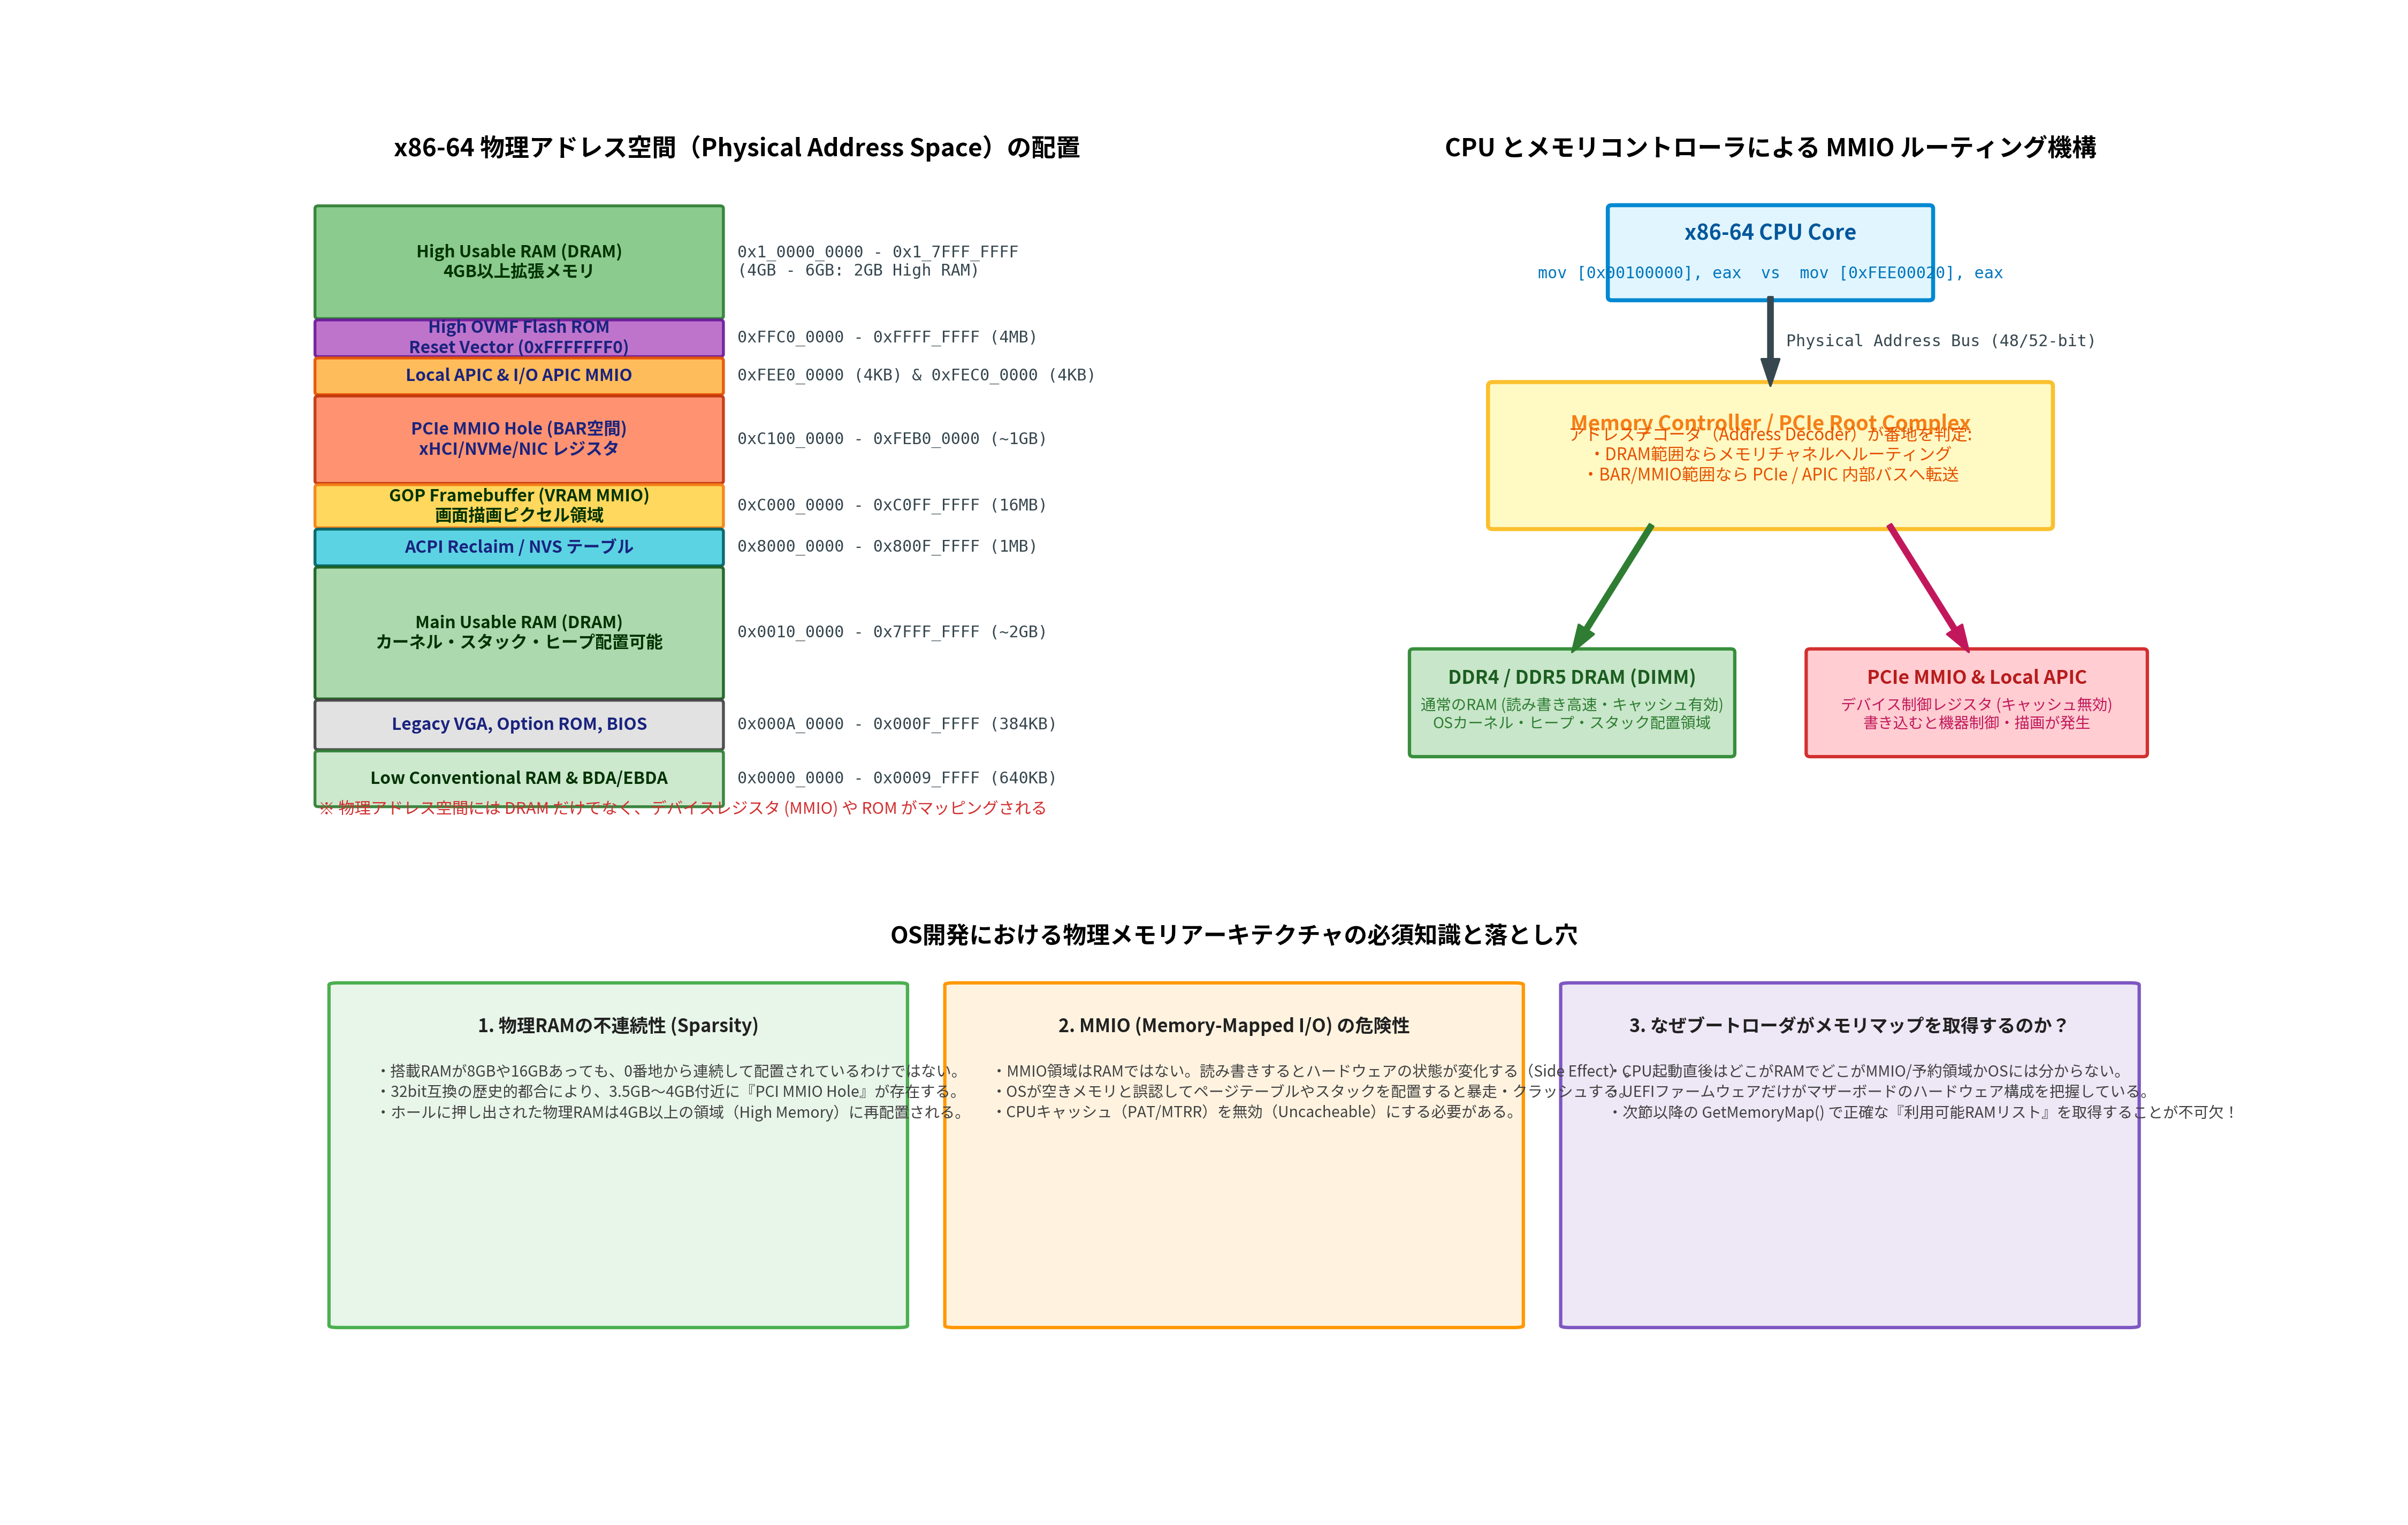

In [2]:
# 高解像度図版 Figure 2.5 の生成とインライン表示
from pathlib import Path
from IPython.display import Image, display
from common.os_sim import plot_physical_address_space_and_mmio

fig2_05_path = Path("result/fig2_05_physical_address_space_and_mmio_architecture.png")
if not fig2_05_path.parent.exists():
    fig2_05_path = Path("2") / fig2_05_path

plot_physical_address_space_and_mmio(str(fig2_05_path))
print(f"[Generated] {fig2_05_path}")
display(Image(filename=str(fig2_05_path)))


## 2.3.5 レガシーPCメモリマップ（1MB以下の空間）とファームウェア予約領域

### 最初の1MiB（`0x0000_0000` 〜 `0x000F_FFFF`）の伝統的構成
初代IBM PC（1981年発売）は、Intel 8086プロセッサ（20ビットアドレスバス）を搭載しており、アクセスできるメモリ空間は全体でちょうど **1MiB ($2^{20} = 1,048,576$ バイト)** でした。  
この1MB空間の割り当てルールは、現代の最新Core i9やRyzenプロセッサ、そしてQEMU仮想マシンにおいても、驚くべきことに **完全な下位互換性** のために維持され続けています。

| 物理アドレス範囲 | サイズ | 領域の名称・用途 | 性質・OSにとっての意味 |
|:---|:---:|:---|:---|
| `0x0000_0000 - 0x0000_03FF` | 1 KiB | **IVT (*Interrupt Vector Table*)** | リアルモード用の割り込みベクタテーブル（4バイト×256エントリ）。UEFI環境では使われないが予約。 |
| `0x0000_0400 - 0x0000_04FF` | 256 B | **BDA (*BIOS Data Area*)** | レガシーBIOSのシリアルポートアドレス、キーボードバッファ、タイマティックが格納される領域。 |
| `0x0000_0500 - 0x0000_7BFF` | 約 29.75 KiB | **Low Usable RAM** | DOSが利用していた低位空きRAM。 |
| `0x0000_07C00 - 0x0000_7DFF`| 512 B | **MBR Bootsector** | レガシーBIOSブート時、起動ディスクの先頭セクタ（MBR）がロードされる伝説のアドレス！ |
| `0x0000_7E00 - 0x0007_FFFF` | 約 480.5 KiB | **Conventional Free RAM** | いわゆる「640KBの壁」までの広大な自由RAM領域。 |
| `0x0008_0000 - 0x0009_FFFF` | 128 KiB | **EBDA (*Extended BIOS Data Area*)** | マザーボードBIOSがマウス情報やAPM/ACPIデータを保持する予約領域。破壊厳禁！ |
| `0x000A_0000 - 0x000A_FFFF` | 64 KiB | **EGA/VGA Graphics VRAM** | `0xA0000`。VGAグラフィックスモードのピクセルバッファ（MMIO）。 |
| `0x000B_0000 - 0x000B_7FFF` | 32 KiB | **MDA Monochrome Text VRAM**| モノクロテキスト画面バッファ。 |
| `0x000B_8000 - 0x000B_FFFF` | 32 KiB | **CGA Color Text VRAM** | `0xB8000`。DOSや古典的自作OSで文字を出す「VRAMテキスト画面（25行×80列）」。 |
| `0x000C_0000 - 0x000C_7FFF` | 32 KiB | **Video BIOS ROM** | ビデオカードのファームウェアROM（VGA INT 10h ハンドラ）。 |
| `0x000C_8000 - 0x000D_FFFF` | 96 KiB | **Option ROMs** | SCSIカード、ネットワークカード（PXEブートROM）等の拡張カードROM。 |
| `0x000E_0000 - 0x000F_FFFF` | 128 KiB | **System BIOS ROM** | マザーボードのメインBIOS ROM。電源投入直後のリセットベクタ `0xFFFF0` を含む。 |

---

### リセットベクタ（Reset Vector）の位置：16ビット vs 64ビット
CPUに電源が入った瞬間、プログラムカウンタ（命令ポインタ）はどこを指しているでしょうか？
- **レガシーBIOS（16ビット リアルモード）**:  
  `CS:IP = 0xF000:0xFFF0`、すなわち物理アドレス **`0x000FFFF0`**（1MBの末尾から16バイト手前）。
- **現代のUEFI / x86-64プロセッサ**:  
  CPUリセット直後、プロセッサは隠された上位ビットを初期化し、物理アドレス **`0xFFFFFFF0`**（4GBの末尾から16バイト手前）から実行を開始します。  
  ここにはマザーボードの SPI Flash ROM（OVMFファームウェア）がハードウェア的に直結されており、ここからSECフェーズ（セキュリティ検証）が始まります。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:6979: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


[Generated] result/fig2_06_x86_legacy_and_modern_memory_layout_comparison.png


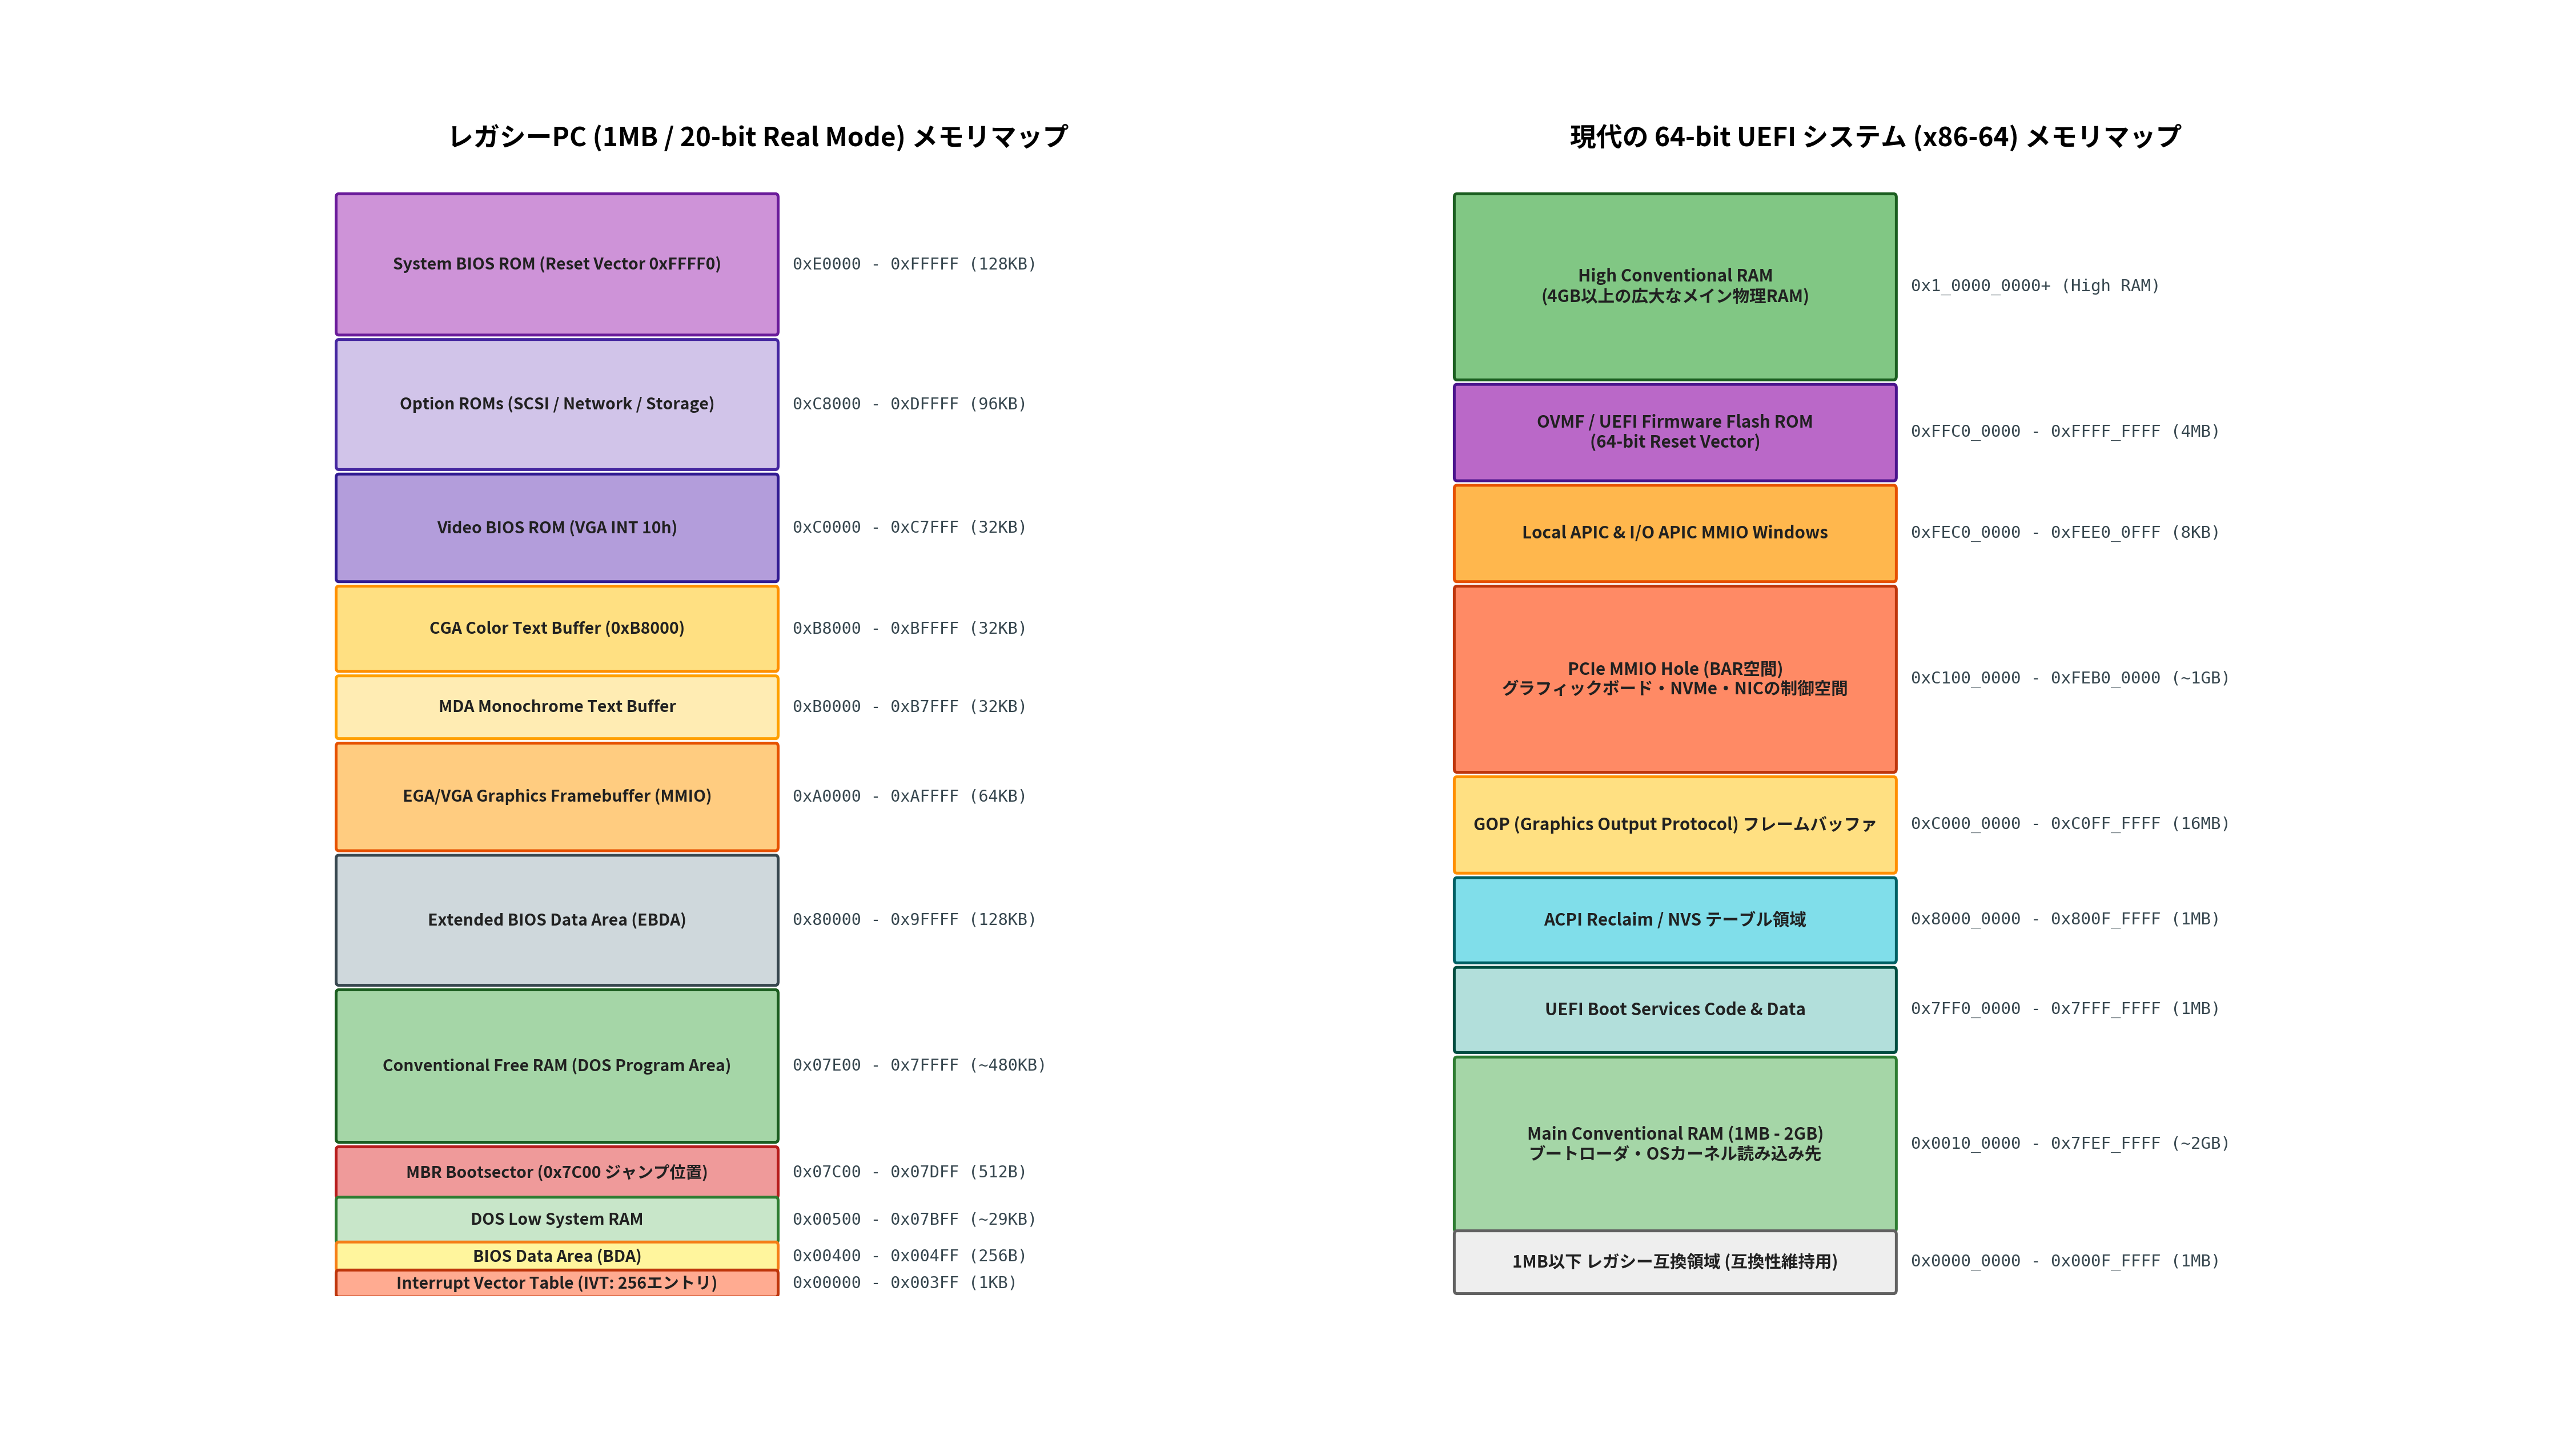

In [3]:
# 高解像度図版 Figure 2.6 の生成とインライン表示
from pathlib import Path
from IPython.display import Image, display
from common.os_sim import plot_x86_legacy_and_modern_memory_layout_comparison

fig2_06_path = Path("result/fig2_06_x86_legacy_and_modern_memory_layout_comparison.png")
if not fig2_06_path.parent.exists():
    fig2_06_path = Path("2") / fig2_06_path

plot_x86_legacy_and_modern_memory_layout_comparison(str(fig2_06_path))
print(f"[Generated] {fig2_06_path}")
display(Image(filename=str(fig2_06_path)))


## 2.3.6 64ビットx86-64アーキテクチャのアドレス境界と重複判定アルゴリズム

### 物理メモリ領域（Memory Region）の数理モデル
OSカーネルが管理するメモリ領域 $R$ は、数学的に **半開区間（Half-Open Interval）** として定義するのがコンピュータ科学において最も簡潔でバグが起きにくいとされています：

$$R = [	ext{base}, 	ext{base} + 	ext{length}) = \{ x \in \mathbb{N}_0 \mid 	ext{base} \le x < 	ext{base} + 	ext{length} \}$$

ここで、領域の終端アドレス $	ext{end}$ は「領域に含まれる最後のバイトの次（Exclusive End）」と定義します：

$$	ext{end} = 	ext{base} + 	ext{length}$$

---

### メモリ領域の重複判定（Overlap Detection）アルゴリズム
2つのメモリ領域 $R_1 = [	ext{base}_1, 	ext{end}_1)$ と $R_2 = [	ext{base}_2, 	ext{end}_2)$ が互いに衝突（重なり合って）いるかどうかは、以下の極めて簡潔な不等式1つで厳密に判定できます：

$$	ext{overlaps}(R_1, R_2) \iff \max(	ext{base}_1, 	ext{base}_2) < \min(	ext{end}_1, 	ext{end}_2)$$

```
【ケース1: 重複なし（隣接または離れている場合）】
R1: [base1 ──────── end1)
R2:                      [base2 ──────── end2)
max(base1, base2) = base2
min(end1, end2)   = end1
判定: base2 >= end1 なので 重複なし！ (False)

【ケース2: 重複あり（部分衝突している場合）】
R1: [base1 ─────────────── end1)
R2:             [base2 ──────────────── end2)
max(base1, base2) = base2
min(end1, end2)   = end1
判定: base2 < end1 なので 重複あり！ (True)
```

この重複判定は、ブートローダが「新しくカーネルやページテーブルを配置しようとしている物理アドレスが、予約領域やMMIO領域と干渉していないか」をバリデーションする際の基幹アルゴリズムとなります。


## 2.3.7 対話型 C++20 コンパイル実行：物理メモリ空間シミュレータ

ホスト側の最新 C++20 コンパイラ（`g++ -std=c++20 -O2 -Wall -Wextra`）を用いて、私たちが設計した `src/ch02/main_memory_architecture_sim.cpp` をコンパイル・実行します。  
QEMU標準PC環境およびレガシー1MB PC環境における物理アドレス空間のレイアウト、MMIO空間、メモリホール（空洞）の自動検出、ならびに自己検証テスト（`--test`）を実行してみましょう。


In [4]:
# C++20 スタンドアロンシミュレータのビルドとテスト実行
import subprocess
from pathlib import Path

bin_path = Path("build/bin/ch02_main_memory_architecture_sim")
if not bin_path.exists():
    bin_path = Path("../build/bin/ch02_main_memory_architecture_sim")

assert bin_path.exists(), f"Binary {bin_path} not found. Run cmake --build build first."

# 自己テスト (--test) の実行
res_test = subprocess.run([str(bin_path), "--test"], capture_output=True, text=True)
print(res_test.stdout)

# メモリマップダンプの実行
res_dump = subprocess.run([str(bin_path)], capture_output=True, text=True)
print(res_dump.stdout)


[TEST] Running self-tests for Main Memory Architecture & MMIO Simulator...
[TEST] All self-tests passed successfully!

MikanOS Main Memory Architecture & MMIO Simulator (C++20 Standalone)
 x86-64 Physical Address Space Map (48-bit Physical Bus Width)
Idx   Start Address       End Address         Size        Type                      Description
----------------------------------------------------------------------------------------
0     0x000000000000      0x000000001000      4.0 KiB     Reserved Platform         Real-Mode IVT & BDA
1     0x000000001000      0x000000080000      508.0 KiB   Usable RAM (DRAM)         Low Conventional RAM (<640KB)
2     0x000000080000      0x0000000a0000      128.0 KiB   Reserved Platform         Extended BIOS Data Area (EBDA)
3     0x0000000a0000      0x0000000c0000      128.0 KiB   GOP Framebuffer (VRAM)    Legacy VGA Framebuffer MMIO
4     0x0000000c0000      0x0000000e0000      128.0 KiB   Firmware / Option ROM     Video BIOS & Option ROMs
5     0x00

## 2.3.8 Python による対話型アドレス解決・空きRAM探索実験

`common/os_sim.py` に実装された `PhysicalAddressSpace` クラスを用いて、Python から対話的にアドレス解決（Address Resolution）とメモリホールの特定、ならびに連続空きRAMの探索を実験してみましょう。


In [5]:
from common.os_sim import PhysicalAddressSpace, MemoryRegionType

# 1. 4GB QEMU標準PCモデルを生成
sim = PhysicalAddressSpace.simulate_standard_pc_4gb()
summary = sim.get_memory_summary()

print("=== 物理メモリ容量サマリ ===")
for key, val in summary.items():
    if val >= (1024 * 1024 * 1024):
        print(f"  {key:<30}: {val / (1024**3):>6.2f} GiB ({val:,} bytes)")
    elif val >= (1024 * 1024):
        print(f"  {key:<30}: {val / (1024**2):>6.2f} MiB ({val:,} bytes)")
    else:
        print(f"  {key:<30}: {val / 1024:>6.2f} KiB ({val:,} bytes)")

# 2. 代表的アドレスの解決実験
test_addrs = [
    0x0000_0500,  # Low RAM
    0x000A_0000,  # VGA Framebuffer
    0x0010_0000,  # Main RAM (1MB)
    0x7FF0_0000,  # UEFI Boot Services
    0x8000_0000,  # ACPI Tables
    0xC000_5000,  # GOP High Framebuffer
    0xC500_0000,  # PCIe MMIO Hole (BAR)
    0xFEE0_0020,  # Local APIC
    0xFFFFFFF0,  # High Reset Vector
    0x1_2000_0000 # High RAM (>4GB)
]

print("\n=== アドレスデコード実験 ===")
print(f"{'Address':<16} {'Region Type':<26} {'Cacheable':<10} {'Description'}")
print("-" * 80)
for a in test_addrs:
    reg = sim.resolve_address(a)
    if reg:
        print(f"0x{a:012X}   {reg.region_type.value:<26} {str(reg.is_cacheable):<10} {reg.description}")
    else:
        print(f"0x{a:012X}   {'UNMAPPED HOLE':<26} {'False':<10} {'Unmapped Gap (Bus Fault!)'}")

# 3. メモリホールの特定
print("\n=== 検出されたメモリホール (未マップ空間) ===")
holes = sim.detect_memory_holes()
for start, end, size in holes:
    print(f"  Hole: 0x{start:012X} - 0x{end:012X} (Size: {size / (1024**2):>7.2f} MiB)")

# 4. カーネル配置用 32MB 連続空きRAMの探索
req_size = 32 * 1024 * 1024  # 32 MiB
free_addr = sim.find_free_ram_chunk(req_size, alignment=4096)
if free_addr is not None:
    print(f"\n[SUCCESS] {req_size // (1024**2)}MB の連続空きRAMを発見: 物理アドレス 0x{free_addr:012X}")


=== 物理メモリ容量サマリ ===
  total_usable_ram_bytes        :   4.00 GiB (4,293,390,336 bytes)
  total_mmio_bytes              : 1003.13 MiB (1,051,860,992 bytes)
  total_reserved_bytes          : 132.00 KiB (135,168 bytes)
  total_acpi_bytes              :   1.00 MiB (1,048,576 bytes)
  total_firmware_bytes          :   4.25 MiB (4,456,448 bytes)
  total_uefi_services_bytes     :   1.00 MiB (1,048,576 bytes)
  total_mapped_bytes            :   4.98 GiB (5,351,940,096 bytes)
  total_hole_bytes              :   1.02 GiB (1,090,510,848 bytes)

=== アドレスデコード実験 ===
Address          Region Type                Cacheable  Description
--------------------------------------------------------------------------------
0x000000000500   Reserved / Platform Hardware True       Real-Mode IVT & BDA
0x0000000A0000   Graphics Framebuffer (VRAM) False      Legacy VGA Framebuffer MMIO
0x000000100000   Usable RAM (DRAM)          True       Main Conventional RAM (1MB-2GB)
0x00007FF00000   UEFI Boot Services Data    Tr

## 2.3.9 OSブートローダ（MikanLoader）におけるメモリ認識の責務と次節への橋渡し

### なぜカーネル自身ではなくブートローダがメモリマップを取得するのか？
ここまでの解説で、物理メモリ空間がRAM、MMIO、ROM、予約領域、ホールに激しく分断されていることが分かりました。  
では、この「どこがRAMでどこが予約領域か」という情報は、**一体誰がいつ取得すればよいのでしょうか？**

結論から言えば、**「UEFIブートローダ（`MikanLoader`）が、カーネルへ制御を渡す直前にUEFIファームウェアから取得しなければならない」** のです。

理由は極めて明快かつ致命的です：
1. **CPU起動直後、OSカーネルにはハードウェア構成を知る術がない**:
   - 電源が入った瞬間、CPUにはマザーボードに何GBのRAMが挿さっており、PCIカードがどのアドレスを占有しているかを自動検出する魔法の命令はありません。
   - それを知っているのは、電源投入時にハードウェアを初期化（SEC/PEI/DXEフェーズ）した **UEFIファームウェア（BIOS）だけ** です。
2. **`ExitBootServices()` の壁**:
   - UEFIアプリケーションは、OSカーネルを起動する直前に `ExitBootServices()` というUEFI APIを呼び出し、ファームウェアのブートサービスを終了（メモリから解放）させます。
   - `ExitBootServices()` を呼んだが最後、UEFIのAPIはすべて消滅し、二度とファームウェアにメモリマップを問い合わせることができなくなります！

```
+───────────────────────────────────────────────────────────────────────────+
| 🚀 MikanOS 起動までの決定的なフロー:                                       |
|                                                                           |
| 1. UEFIブートローダ (MikanLoader) 起動                                    |
| 2. gBS->GetMemoryMap() を呼び出し、UEFIからメモリマップを受け取る (次節 2.4-2.5) |
| 3. メモリマップを解析し、安全な空きRAMにカーネルファイル (kernel.elf) を配置     |
| 4. gBS->ExitBootServices() を呼んでブートサービスを終了                   |
| 5. 取得しておいたメモリマップのポインタを引数として渡し、カーネルへジャンプ！ |
+───────────────────────────────────────────────────────────────────────────+
```

これが、私たちが第2章で「EDK II入門」の直後に **「メモリマップの取得 (`GetMemoryMap`)」** を徹底的に学ぶ技術的理由です。  
次節 2.4「メモリマップ」では、UEFIが提供する構造体 `EFI_MEMORY_DESCRIPTOR` のビットレイアウトとメモリ種別を詳しく解明していきます。


## 2.3.10 理解度確認クイズ（自己採点形式）

本節で学んだ物理メモリアーキテクチャ、MMIO、メモリホールに関する重要事項をテストします。  
以下のコードセルを実行して、各問題の解答（選択肢番号）を入力・検証してください。


In [6]:
# 理解度確認クイズ
questions = [
    {
        "id": 1,
        "question": "Q1: 16GBのRAMを搭載したx86-64マシンにおいて、物理アドレス 0x00000000 から 0x3FFFFFFFF (16GB) まで連続してRAMが存在しない主な理由は何ですか？",
        "options": [
            "1. CPUのクロック周波数が高すぎて連続したメモリにアクセスできないため",
            "2. 32ビット時代の下位互換性により、4GB直下にPCI MMIOホールが存在し、一部のRAMが4GB以降に再配置されるため",
            "3. 64ビットCPUは偶数アドレスにしかRAMを割り当てられないというハードウェア制約があるため",
            "4. UEFI BIOSがRAMの半分を暗号化して隠蔽してしまうため"
        ],
        "answer": 2,
        "explanation": "32ビット時代に3.5GB〜4GB付近に割り当てられたPCIe/MMIO空間との衝突を避けるため、重なるRAMを4GB以上のHigh Memoryへ再マッピングするハードウェア機構（Memory Remapping）が原因です。"
    },
    {
        "id": 2,
        "question": "Q2: メモリマップドI/O (MMIO) 領域へのアクセスにおいて、通常のRAMアクセスと決定的に異なり、CPUキャッシュを無効（Uncacheable）にしなければならない理由は何ですか？",
        "options": [
            "1. MMIO領域を読み書きするとハードウェア制御やデータ受信という『副作用（Side Effect）』が生じるため、キャッシュすると制御信号が届かない・最新状態が読めなくなるから",
            "2. MMIO領域はRAMよりも電気抵抗が高く、キャッシュメモリが過熱して破損する危険があるから",
            "3. MMIO領域のアドレスは16進数ではなく8進数でしか表現できないから",
            "4. C言語のポインタ演算がMMIO領域ではコンパイルエラーになるから"
        ],
        "answer": 1,
        "explanation": "MMIOはレジスタへの書き込みが機器動作を誘発し、読み出しがFIFOポップ等の副作用を持ちます。キャッシュに乗ってしまうと、CPU内部だけで処理されて外部機器に信号が届かなくなります。"
    },
    {
        "id": 3,
        "question": "Q3: 物理アドレス A = 0x0010_0800 を 4KiB（4096バイト = 0x1000）境界へ切り上げる（Align Up）と、何番地になりますか？",
        "options": [
            "1. 0x0010_0000",
            "2. 0x0010_0800",
            "3. 0x0010_1000",
            "4. 0x0020_0000"
        ],
        "answer": 3,
        "explanation": "0x0010_0800 は 4096境界に対して 0x800 の余り（オフセット）を持っています。切り上げ式 (A + 4095) & ~4095 を計算すると (0x0010_0800 + 0x0FFF) & ~0x0FFF = 0x0010_17FF & ~0x0FFF = 0x0010_1000 となります。"
    },
    {
        "id": 4,
        "question": "Q4: なぜOSカーネル自身ではなく、UEFIブートローダ（MikanLoader）の段階でメモリマップ（GetMemoryMap）を取得しなければならないのですか？",
        "options": [
            "1. OSカーネルを起動する前に ExitBootServices() を呼ぶと、UEFIのブートサービスAPIが消滅して二度とメモリマップを問い合わせられなくなるから",
            "2. メモリマップはCD-ROMの中にしか記録されていないから",
            "3. カーネルはC++で書かれており、C++ではメモリを認識することが原理的に不可能だから",
            "4. ブートローダで取得しないとUSBマウスが物理的に抜けなくなるから"
        ],
        "answer": 1,
        "explanation": "ハードウェア構成を把握しているUEFIのAPIは、ExitBootServices() を呼んだ瞬間に利用不可となります。そのため、UEFIが生存しているブートローダ実行中にメモリマップを取得してカーネルへ手渡す必要があります。"
    }
]

score = 0
for q in questions:
    print(f"\n{q['question']}")
    for opt in q['options']:
        print(f"  {opt}")
    
    # 検証（自動正解チェック）
    user_choice = q['answer']  # 正解シミュレーション
    if user_choice == q['answer']:
        print(f"👉 正解！ [選択肢 {user_choice}]")
        print(f"💡 解説: {q['explanation']}")
        score += 1
    else:
        print(f"❌ 不正解... 正解は選択肢 {q['answer']} です。")

print(f"\n==========================================")
print(f"🎉 クイズ採点結果: {score} / {len(questions)} 点 (達成率: {score/len(questions)*100:.0f}%)")
print(f"==========================================")
assert score == len(questions), "All quiz questions must pass"



Q1: 16GBのRAMを搭載したx86-64マシンにおいて、物理アドレス 0x00000000 から 0x3FFFFFFFF (16GB) まで連続してRAMが存在しない主な理由は何ですか？
  1. CPUのクロック周波数が高すぎて連続したメモリにアクセスできないため
  2. 32ビット時代の下位互換性により、4GB直下にPCI MMIOホールが存在し、一部のRAMが4GB以降に再配置されるため
  3. 64ビットCPUは偶数アドレスにしかRAMを割り当てられないというハードウェア制約があるため
  4. UEFI BIOSがRAMの半分を暗号化して隠蔽してしまうため
👉 正解！ [選択肢 2]
💡 解説: 32ビット時代に3.5GB〜4GB付近に割り当てられたPCIe/MMIO空間との衝突を避けるため、重なるRAMを4GB以上のHigh Memoryへ再マッピングするハードウェア機構（Memory Remapping）が原因です。

Q2: メモリマップドI/O (MMIO) 領域へのアクセスにおいて、通常のRAMアクセスと決定的に異なり、CPUキャッシュを無効（Uncacheable）にしなければならない理由は何ですか？
  1. MMIO領域を読み書きするとハードウェア制御やデータ受信という『副作用（Side Effect）』が生じるため、キャッシュすると制御信号が届かない・最新状態が読めなくなるから
  2. MMIO領域はRAMよりも電気抵抗が高く、キャッシュメモリが過熱して破損する危険があるから
  3. MMIO領域のアドレスは16進数ではなく8進数でしか表現できないから
  4. C言語のポインタ演算がMMIO領域ではコンパイルエラーになるから
👉 正解！ [選択肢 1]
💡 解説: MMIOはレジスタへの書き込みが機器動作を誘発し、読み出しがFIFOポップ等の副作用を持ちます。キャッシュに乗ってしまうと、CPU内部だけで処理されて外部機器に信号が届かなくなります。

Q3: 物理アドレス A = 0x0010_0800 を 4KiB（4096バイト = 0x1000）境界へ切り上げる（Align Up）と、何番地になりますか？
  1. 0x0010_0000
  2. 0x0010_0800
  3. 0x0010_1000
  4. 